<a href="https://colab.research.google.com/github/samhitardy2801/BharatLoads/blob/main/CASE_STUDY_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch torchvision matplotlib numpy

In [ ]:
import os
import numpy as np
import pandas as pd
import random
import time
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings("ignore")


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device:", device)

Using Device: cuda


In [ ]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"samhitardy2801","key":"677114f8b7534939f485b34e41c1ff41"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
 97% 2.24G/2.29G [00:15<00:00, 92.5MB/s]
100% 2.29G/2.29G [00:15<00:00, 156MB/s] 


In [ ]:
!unzip chest-xray-pneumonia.zip

Streaming output truncated to the last 5000 lines.
  inflating: chest_xray/train/NORMAL/IM-0435-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0435-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0437-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0438-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001-0002.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0439-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0440-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0441-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0442-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0444-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0445-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0446-0001.jpeg  
  inflating: chest_xray/train/NORMAL/IM-0447-0001.jpeg  
  inflating:

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

train_data = datasets.ImageFolder(
    "/content/chest_xray/train",
    transform=transform
)

test_data = datasets.ImageFolder(
    "/content/chest_xray/test",
    transform=transform
)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1, shuffle=False)

class_names = train_data.classes
print("Classes:", class_names)

Classes: ['NORMAL', 'PNEUMONIA']


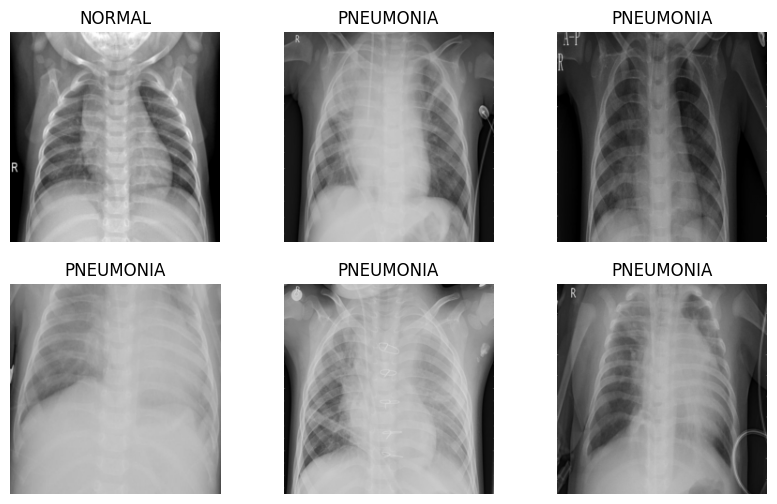

In [ ]:
def show_images():
    images, labels = next(iter(train_loader))
    plt.figure(figsize=(10,6))
    for i in range(6):
        plt.subplot(2,3,i+1)
        plt.imshow(images[i].permute(1,2,0))
        plt.title(class_names[labels[i]])
        plt.axis("off")
    plt.show()

show_images()

In [ ]:
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*28*28, 256),
            nn.ReLU(),
            nn.Dropout(0.5),   # Important for Monte Carlo Dropout
            nn.Linear(256, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

model = CNNModel()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

In [ ]:
import torch.optim as optim

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(3):  # Increase for better accuracy
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {running_loss/len(train_loader)}")

Epoch 1, Loss: 0.2821556427773157
Epoch 2, Loss: 0.12496643156410292
Epoch 3, Loss: 0.09896837676835298


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print("Test Accuracy:", 100 * correct / total)

Test Accuracy: 74.51923076923077


In [ ]:
def mc_dropout_predict(model, image, n_samples=20):
    model.train()  # Keep dropout ON

    predictions = []

    for _ in range(n_samples):
        output = model(image)
        prob = torch.softmax(output, dim=1)
        predictions.append(prob.detach().cpu().numpy())

    predictions = np.array(predictions)

    mean_prediction = predictions.mean(axis=0)
    uncertainty = predictions.std(axis=0)

    return mean_prediction, uncertainty

In [ ]:
model.eval()

image, label = next(iter(test_loader))
image = image.to(device)

mean_pred, uncertainty = mc_dropout_predict(model, image)

confidence = np.max(mean_pred)
uncertainty_score = np.mean(uncertainty)

predicted_class = class_names[np.argmax(mean_pred)]

print("Prediction:", predicted_class)
print("Confidence:", round(float(confidence),3))
print("Uncertainty:", round(float(uncertainty_score),3))

if uncertainty_score > 0.15:
    print("⚠ Needs Senior Doctor Review")
else:
    print("✅ AI Suggestion Accepted")

Prediction: PNEUMONIA
Confidence: 0.524
Uncertainty: 0.271
⚠ Needs Senior Doctor Review


Accuracy Score: 0.7451923076923077
Confusion Matrix:
 [[ 79 155]
 [  4 386]]


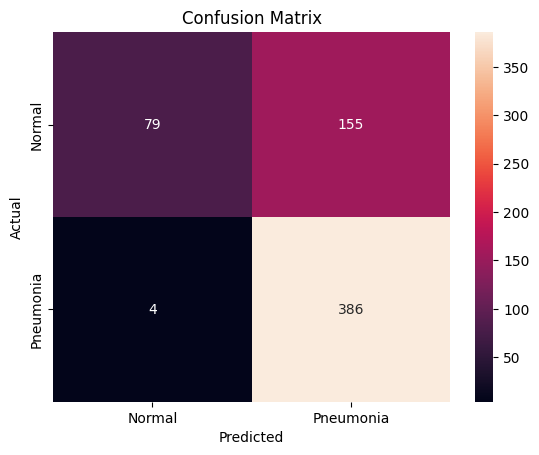

              precision    recall  f1-score   support

      Normal       0.95      0.34      0.50       234
   Pneumonia       0.71      0.99      0.83       390

    accuracy                           0.75       624
   macro avg       0.83      0.66      0.66       624
weighted avg       0.80      0.75      0.71       624



In [26]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# Accuracy
acc = accuracy_score(all_labels, all_preds)
print("Accuracy Score:", acc)

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
print("Confusion Matrix:\n", cm)

# Plot
plt.figure()
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=["Normal", "Pneumonia"],
            yticklabels=["Normal", "Pneumonia"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Report
print(classification_report(all_labels, all_preds,
                            target_names=["Normal", "Pneumonia"]))

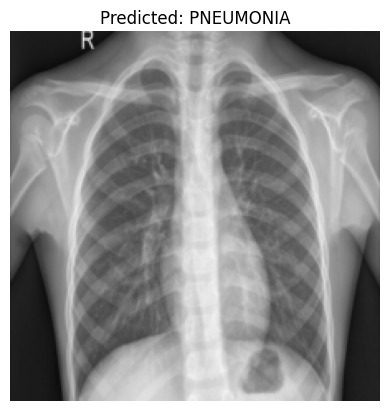

In [ ]:
plt.imshow(image.cpu()[0].permute(1,2,0))
plt.title(f"Predicted: {predicted_class}")
plt.axis("off")
plt.show()

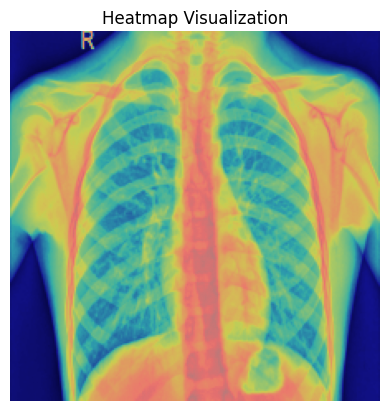

In [ ]:
def simple_heatmap(image_tensor):
    image_np = image_tensor.cpu()[0].permute(1,2,0).numpy()
    heatmap = np.mean(image_np, axis=2)

    plt.imshow(image_np)
    plt.imshow(heatmap, cmap='jet', alpha=0.5)
    plt.title("Heatmap Visualization")
    plt.axis("off")
    plt.show()

simple_heatmap(image)